# **Multi-tool ReAct agents for biomedical question answering**

In this notebook we build and study an LLM agent that answers biomedical questions by deciding **which tool to call and when**,
and we ask a simple question: *does dynamic orchestration really beat a fixed retrieval pipeline?*

We will tackle the following tasks:
> 1. Prepare **PaperSearchQA**, a QA dataset built on PubMed abstracts, and a local search index with several embedding models.
> 2. Build a no-tool baseline and four **fixed chains** (static RAG).
> 3. Implement **five tools** (local retrieval, live PubMed, OpenFDA, query reformulator, reasoning query).
> 4. Build a **ReAct agent with LangGraph** and compare it with the baselines (experiments 1 and 2).
> 5. **Read the traces**: tool choices per question category, failure modes, and why the agent behaves as it does (experiment 3).

📝 Luyao Ma  ·  project proposal by Lorenzo Molfetta  ·  *Big Data Analytics and Text Mining*, University of Bologna

## 📜 Outline
1. Set up: packages, secrets, GPU
2. Dataset: PaperSearchQA
3. Local retrieval and the embedding models
3b. Two classical baselines: BM25 and a BM25 + dense hybrid
4. The LLM, the answer prompt and the metrics
5. Baselines: no tools and fixed chains
6. Tool definition: five tools
7. The ReAct agent in LangGraph
8. Experiment 1: which tool contributes?
9. Experiment 2: fixed chain vs dynamic orchestrator
10. Experiment 3: what does the agent actually do? (trace analysis)
11. Granite vs MedGemma as the scheduler
12. An extra look: paraphrased questions (12b prompt sensitivity, 12c fixed-chain ranking, 12d held-out validation, 12e coverage experiment)
13. Discussion, limitations and related work
14. Reproducibility

## ⚙️ 1. Set Up: Packages, Secrets, GPU

> **Where is the data?** This notebook expects the repository layout (`scripts/`, `data/`, `results/`, `traces/`).
> On Colab, upload `bigdata_project.zip` and run the unzip cell below. All **tables and figures are read from `results/`**,
> so only the small *live demos* need a GPU (switch `LIVE`).

In [1]:
# Unzip the submission archive if we are on Colab; go to the project root if opened from notebook/
import os, zipfile, pathlib
if pathlib.Path("bigdata_project.zip").exists() and not pathlib.Path("scripts").exists():
    zipfile.ZipFile("bigdata_project.zip").extractall(".")
    os.chdir("bigdata_project")
if not pathlib.Path("scripts").exists() and pathlib.Path("../scripts").exists():   # opened from notebook/
    os.chdir("..")
print("project folder:", pathlib.Path.cwd().name, "|", sorted(os.listdir("."))[:8])

project folder: bigdata_project | ['README.md', 'cache', 'data', 'env', 'notebook', 'results', 'scripts', 'traces']


In [2]:
# 📦 Packages. Pinned: the ones Colab does not ship (exact versions of everything, torch 2.11.0 and numpy/pandas/scipy/matplotlib included, are in env/requirements.txt).
# numpy / pandas / scipy / matplotlib / torch are left at the preinstalled versions to avoid conflicts; the notebook was NOT tested on Colab, only on a laptop (results-only mode).
%pip install -q transformers==5.20.2 sentence-transformers==6.2.0 faiss-cpu==1.15.1 langgraph==1.2.16 langchain-core==1.7.0 metapub==0.7.5 datasets==5.1.0 rouge-score==0.1.2

> **RESTART** the runtime after the installation, then continue from the next cell.

In [3]:
import json, gzip, re, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
warnings.filterwarnings("ignore")

if not Path("scripts").exists() and Path("bigdata_project/scripts").exists():    # Colab: after the runtime restart we are back in /content
    import os; os.chdir("bigdata_project")
ROOT = Path(".")
sys.path.insert(0, str(ROOT / "scripts"))          # our modules: qa_utils, prompts, tools, agent, ...
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def have(p):
    ok = (ROOT / p).exists()
    if not ok: print(f"(not found: {p}) -> run the step described in README.md")
    return ok

We use **open-source models from Hugging Face**. MedGemma is a *gated* model: accept its license on the model page and paste your key
into the Colab `Secrets` 🔑 (`HF_TOKEN`). `NCBI_API_KEY` (free) makes PubMed 3× faster. Never write keys in the notebook.

In [4]:
import os
for name in ("HF_TOKEN", "NCBI_API_KEY"):
    try:
        from google.colab import userdata
        os.environ[name] = userdata.get(name)         # Colab Secrets
    except Exception:
        pass                                          # locally / on the cluster: use environment variables
print({k: ("set" if os.environ.get(k) else "missing") for k in ("HF_TOKEN", "NCBI_API_KEY")})

{'HF_TOKEN': 'missing', 'NCBI_API_KEY': 'missing'}


### 🖥️ GPU and numeric precision

MedGemma must run in **bfloat16**: in float16 it overflows and returns *empty* answers (we measured this).
Turing GPUs (Colab **T4**, RTX 2080 Ti) have no native bf16 but run it through emulation: slower (about half the speed), yet correct.

In [5]:
LIVE = False
try:
    import torch
except ImportError:
    torch = None
    print("torch is not installed: live demos disabled")
if torch is not None and torch.cuda.is_available():
    mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(torch.cuda.get_device_name(0), f"| {mem:.0f} GB | bf16 native:", torch.cuda.get_device_capability(0)[0] >= 8)
    LIVE = mem >= 15          # MedGemma-4B needs ~9 GB of weights + cache; the retriever model fits next to it
print("LIVE demos enabled:", LIVE)

torch is not installed: live demos disabled
LIVE demos enabled: False


# 📚 2. Dataset: PaperSearchQA

**PaperSearchQA** (Burgess et al., EACL 2026) contains factoid questions generated by GPT-4.1 from PubMed abstracts
(three questions per abstract, ten expert-defined categories in the paper (our HuggingFace copy has eleven, `cat_num` 0-10, where 0 = "Other"), 50 % of the questions paraphrased to reduce keyword overlap).
The dataset gives the *question, answer, synonyms, PMID, category* but **not the paper text**: we fetch the abstracts with `metapub`.

Our sample (`scripts/01_sample_data.py`): **500 questions**, seed 42, one question per PMID, proportional per category with a floor of 20.

In [6]:
if have("data/sample.jsonl"):
    sample = pd.read_json(ROOT / "data" / "sample.jsonl", lines=True)
    print(len(sample), "questions |", sample.pmid.nunique(), "distinct papers |", f"{sample.is_paraphrased.mean():.0%} paraphrased")
    display(sample.groupby(["cat_num", "cat"]).size().rename("questions").to_frame())
    display(sample[["question", "answer", "cat", "is_paraphrased"]].head(5))

500 questions | 500 distinct papers | 54% paraphrased


,,questions
cat_num,cat,
0,Other,20
1,Genetic mutations,20
2,Therapeutics & clinical evidence,83
3,Protein function & signalling,62
4,Methods & resources,97
5,Disease causation & pathogens,61
6,Biomarkers & diagnostics,55
7,Bioinformatics databases,20
8,Clinical scales & classifications,20


,question,answer,cat,is_paraphrased
0,What tumor marker is commonly elevated in the ...,Alpha-fetoprotein,Biomarkers & diagnostics,False
1,Which rare-earth element is commonly incorpora...,Gadolinium,Therapeutics & clinical evidence,False
2,Which blood lipid showed an increased concentr...,Triglycerides,Biomarkers & diagnostics,False
3,What group of compounds produced in the colon ...,Short-chain fatty acids,Protein function & signalling,False
4,What is the name of the evidence-based HIV pre...,Healthy Relationships,Therapeutics & clinical evidence,False


### 🧾 The corpus: gold abstracts and distractors

The local index holds the 500 gold abstracts **plus 4,500 distractor abstracts** (other papers of the same dataset).
Why? With only the 500 gold papers, retrieval is almost perfect (Recall@10 = 0.99) and no tool can show an effect.
We therefore measure everything on the 5,000-document index.

In [7]:
if have("data/corpus.jsonl") and have("data/corpus_distractors.jsonl"):
    gold = pd.read_json(ROOT / "data" / "corpus.jsonl", lines=True)
    dist = pd.read_json(ROOT / "data" / "corpus_distractors.jsonl", lines=True)
    print(len(gold), "gold abstracts +", len(dist), "distractors")
    display(gold[["pmid", "title", "journal", "year"]].head(3))

500 gold abstracts + 4500 distractors


,pmid,title,journal,year
0,15265907,Alpha-fetoprotein impairs APC function and ind...,J Immunol,2004
1,24237132,Incorporation of computed tomography and magne...,Anal Chem,2013
2,17181072,Changes in the lipid composition of blood plas...,Bull Exp Biol Med,2006


# 🔎 3. Local Retrieval and the Embedding Models

An **embedding model** maps text to a vector so that texts with a similar meaning are close; a **FAISS index** stores the document vectors and
finds the nearest ones to a query vector. We compare three models: `pubmedbert` (biomedical), `jina-embeddings-v5` (general, separate query/document prompts)
and `bge-m3` (general). Each question has exactly **one** relevant paper, hence **MAP = MRR**.

In [8]:
rows = {}
for tag, label in (("", "500 docs"), ("_5k", "5,000 docs")):
    if have(f"results/retrieval_summary{tag}.json"):
        for model, m in json.load(open(ROOT / "results" / f"retrieval_summary{tag}.json")).items():
            rows[(label, model)] = {k: v for k, v in m.items() if k != "encode_seconds"}
if rows:
    display(pd.DataFrame(rows).T.round(3))

Recall@1  Recall@5  Recall@10    MRR    MAP  nDCG@1  nDCG@5  nDCG@10
500 docs   pubmedbert     0.860     0.958      0.980  0.903  0.903   0.860   0.914    0.922
           jina           0.948     0.984      0.990  0.965  0.965   0.948   0.969    0.971
           bge-m3         0.898     0.970      0.984  0.932  0.932   0.898   0.940    0.945
5,000 docs pubmedbert     0.690     0.864      0.902  0.764  0.764   0.690   0.783    0.795
           jina           0.828     0.956      0.970  0.883  0.883   0.828   0.899    0.904
           bge-m3         0.760     0.892      0.928  0.821  0.821   0.760   0.833    0.845

**Reading the table.** With 500 documents retrieval is saturated; adding 4,500 distractors separates the models:
`jina` is the best (Recall@1 0.83 vs 0.76 for `bge-m3` and 0.69 for `pubmedbert`), so a general-purpose model beats the biomedical one here.
All following experiments use `jina` and the 5,000-document index.

## 3b. Two classical retrieval baselines: BM25 and a BM25 + dense hybrid

Every experiment so far uses one very strong dense retriever (`jina`, Recall@10 0.97), which leaves little room for any orchestrator. Here we add the two classical baselines a reader would ask for and measure how much weaker retrieval can get.
**Protocol (fixed before running, no tuning).** Same 5,000 documents (title + abstract), the raw question as the query, 500 development and 500 held-out questions.
- **BM25**: Okapi BM25, k1 = 1.5, b = 0.75, Lucene idf; lower-cased, tokens `[a-z0-9]+`, English stop words removed, no stemming (a limitation: stemming could help BM25).
- **Hybrid**: reciprocal rank fusion of the BM25 and `jina` rankings (top 100 of each, k = 60, equal weights).
- **Metrics**: Recall@1/5/10, MRR, nDCG@10, overall and for original vs paraphrased questions; build time, memory and query latency (laptop CPU for BM25, so only the order of magnitude is comparable with the cluster GPU numbers of `jina`).

| | Prediction (written before the run) |
|---|---|
| B1 | BM25 is clearly weaker than `jina` on the development sample: Recall@1 in [0.55, 0.75], Recall@10 in [0.82, 0.94], at least 0.03 below `jina` (0.970) |
| B2 | BM25 suffers from paraphrasing, dense retrieval does not: Recall@1 on original minus paraphrased questions is at least 0.08 for BM25, below 0.03 in absolute value for `jina` (observed -0.009) |
| B3 | The hybrid is at least as good as `jina` (no more than 0.01 below it on Recall@1, @5 and @10), with Recall@10 in [0.965, 0.99] and Recall@1 in [0.82, 0.88] |
| B4 | The held-out sample shows the same ordering: BM25 Recall@10 at least 0.03 below `jina`; the hybrid no more than 0.01 below `jina` on Recall@1 and Recall@10 |
| B5 | BM25 is far cheaper: building its index for 5,000 documents takes at most 30 s on one CPU core, uses at most 200 MB, answers a query in at most 20 ms, and is at least 10 times faster to build than the 480 s `jina` needs to encode the corpus |

**Decision rule (fixed in advance).** Retrieval-only numbers come first. If BM25 Recall@10 on the development sample is **at most 0.93**, the weaker retriever is informative and we also run the answer chains and the agent with BM25 and the hybrid. If it is above 0.93, we stop and report only the retrieval table.

In [9]:
if have("results/bm25/retrieval_bm25.csv"):
    _r = pd.read_csv(ROOT / "results" / "bm25" / "retrieval_bm25.csv")
    display(_r[_r.subset == "all"].drop(columns="subset").round(3))
    print("Recall@1 by question type (original vs paraphrased):")
    display(_r[_r.subset != "all"].pivot_table(index=["sample", "method"], columns="subset", values="Recall@1").round(3))
    print("BM25 cost (laptop CPU):", {k: (round(v, 2) if isinstance(v, float) else v) for k, v in json.load(open(ROOT / "results" / "bm25" / "timing_macbook_cpu.json")).items() if k != "latency_ms_per_query"})

,sample,method,n,Recall@1,Recall@5,Recall@10,MRR,nDCG@10
0,development,BM25,500,0.774,0.884,0.922,0.827,0.848
3,development,jina (dense),500,0.830,0.956,0.968,0.883,0.904
6,development,hybrid (RRF),500,0.828,0.934,0.954,0.876,0.893
9,held-out,BM25,500,0.802,0.902,0.920,0.844,0.860
12,held-out,jina (dense),500,0.844,0.940,0.956,0.887,0.903
15,held-out,hybrid (RRF),500,0.858,0.934,0.958,0.894,0.908


Recall@1 by question type (original vs paraphrased):


subset                    original  paraphrased
sample      method                             
development BM25             0.873        0.690
            hybrid (RRF)     0.865        0.797
            jina (dense)     0.825        0.834
held-out    BM25             0.865        0.731
            hybrid (RRF)     0.902        0.808
            jina (dense)     0.850        0.838

BM25 cost (laptop CPU): {'machine': 'macbook_cpu', 'documents': 5000, 'build_seconds': 1.22, 'index_mb': 5.7, 'peak_python_mb_while_building': 42.2}


**Result: B2, B4 and B5 held; B1 held in part; B3 did not hold.** (`jina` here is recomputed from its saved top-100 lists, so it differs from the earlier table by one question: 0.968 vs 0.970 Recall@10.)

| | Prediction | Result | |
|---|---|---|---|
| B1 | BM25 Recall@1 in [0.55, 0.75], Recall@10 in [0.82, 0.94], at least 0.03 below `jina` | Recall@1 **0.774**, Recall@10 0.922 (0.046 below `jina`) | **Recall@1 no** (BM25 is stronger than predicted), rest yes |
| B2 | Recall@1 original minus paraphrased: at least 0.08 for BM25, below 0.03 for `jina` | BM25 0.183 (held-out 0.134); `jina` -0.009 (+0.012) | yes |
| B3 | the hybrid is at most 0.01 below `jina` on Recall@1/5/10; Recall@10 in [0.965, 0.99] | Recall@1 -0.002, Recall@5 **-0.022**, Recall@10 **-0.014** (0.954) | **no** |
| B4 | held-out: same ordering | BM25 0.036 below `jina` at Recall@10; the hybrid +0.014 at Recall@1 and +0.002 at Recall@10 | yes |
| B5 | build ≤ 30 s, ≤ 200 MB, ≤ 20 ms/query, ≥ 10 times faster than `jina`'s 480 s | 1.2 s, 42 MB peak (5.7 MB index), 0.21 ms; about 400 times faster (different hardware) | yes |

What we learn:
- **BM25 is a strong baseline.** It is only 4.6 Recall@10 points and 5.6 Recall@1 points below `jina` on the development sample (0.922 vs 0.968, 0.774 vs 0.830), and about the same on the held-out sample (0.920 vs 0.956, 0.802 vs 0.844). We expected a larger gap.
- **The dense retriever's advantage lies entirely in the paraphrased questions.** On the original questions BM25 is as good or better (Recall@1 0.873 vs 0.825 on development, 0.865 vs 0.850 held-out); on the paraphrased ones it drops to 0.690 (0.731) while `jina` stays at 0.834 (0.838).
- **An equal-weight hybrid does not reliably beat the dense retriever.** It is a little worse on development and a little better on held-out data, by a few questions each time (one question is 0.002), i.e. within the noise of 500 questions. We did not tune the fusion weights, by design.
- **Cost:** BM25 is built in about a second on a laptop CPU with a 5.7 MB index and answers in 0.2 ms, while `jina` needs a GPU and about 480 s to encode the corpus.
- **Decision rule:** BM25 Recall@10 on the development sample is 0.922, below the 0.93 threshold, our rule therefore called for running the answer chains and the agent with BM25 and the hybrid as well. **We did not.** BM25 is only about 5 points weaker than `jina` and the hybrid brings no reliable gain, so we expected small downstream differences and stopped at the retrieval table to keep the project's scope in check. This leaves open whether a weaker retriever would change the conclusions about query rewriting and the agent; the coverage experiment of section 12e tests a related question from the other side (missing documents instead of a weaker retriever).

# 🤖 4. The LLM, the Answer Prompt and the Metrics

We use **`google/medgemma-1.5-4b-it`** for everything that needs a language model (answers, the two query-rewriting tools, and the agent's scheduler).
It is loaded **locally with Transformers**, in bf16, with greedy decoding.

In [10]:
if LIVE:
    from llm import MedGemma
    medgemma = MedGemma(dtype="bfloat16")
    print(medgemma.generate(["Answer with one word: what is the capital of France?"], max_new_tokens=8, prefill="A:"))
else:
    print("LIVE is off: skipping the model download (the saved results are used instead)")

LIVE is off: skipping the model download (the saved results are used instead)


### ✍️ The answer prompt: why the model's turn is pre-filled

Asked for a short answer, MedGemma sometimes *starts thinking* (`thought\nThe user wants me to ...`) and never reaches the answer.
In our first run this cost about **7 EM points**. We therefore **pre-fill the model turn with `A:`**, so it answers directly.
Every system in this notebook uses the same prompt and the same answer cleaning, so differences come from the retrieval policy only.

In [11]:
from prompts import answer_prompt, PREFILL
print(answer_prompt("Which imaging technique can identify unilateral hydrocephalus?",
                    "[1] Unilateral hydrocephalus: prenatal sonographic diagnosis. ..."))
print("\n--- the model turn then starts with the pre-filled text:", repr(PREFILL))

You are a biomedical expert. Reply with ONLY the answer: a short noun phrase (at most 6 words), no explanation, no full sentence. When PubMed abstracts are provided, copy the exact term they use, including its modifiers.

Use the PubMed abstracts below if they help.

Context:
[1] Unilateral hydrocephalus: prenatal sonographic diagnosis. ...

Examples of the answer format:
Q: What is the capital of France?
A: Paris

Q: Which gas do plants absorb during photosynthesis?
A: Carbon dioxide

Q: Which imaging technique can identify unilateral hydrocephalus?
A:

--- the model turn then starts with the pre-filled text: 'A:'


### 📏 Metrics

**EM** (exact match): after lower-casing, removing punctuation and articles, the prediction equals the answer or one of its synonyms.
**Contains**: a gold answer appears inside the prediction (more tolerant). **ROUGE-1/L**: word overlap with the best gold answer.
EM is strict: for Vanilla RAG on the development sample *Contains* is 5.6 points above EM (0.820 vs 0.764), i.e. about a quarter of the EM errors still contain a gold answer string. Most are wording differences, but not all (`L4` inside `L4 and L5` is not a correct answer), so this is an upper bound; we did not audit the errors one by one. We therefore also report Contains and ROUGE.

In [12]:
from qa_utils import clean_answer, score_prediction
examples = [("**Short-chain fatty acids (SCFAs)**", ["Short-chain fatty acids"]),
            ("The answer is: MHC-I.", ["MHC-I"]),
            ("Based on the provided abstracts, the answer is:\nDNA or RNA oligonucleotides", ["Oligonucleotides"]),
            ("thought\nThe user wants me to identify ...", ["Multiple sclerosis"])]
for raw, golds in examples:
    s = score_prediction(raw, golds)
    print(f"{raw[:55]!r:60} -> {s['pred']!r:42} EM={s['EM']:.0f} Contains={s['Contains']:.0f}")

'**Short-chain fatty acids (SCFAs)**'                        -> 'Short-chain fatty acids (SCFAs)'          EM=1 Contains=1
'The answer is: MHC-I.'                                      -> 'MHC-I'                                    EM=1 Contains=1
'Based on the provided abstracts, the answer is:\nDNA or '   -> 'DNA or RNA oligonucleotides'              EM=0 Contains=1
'thought\nThe user wants me to identify ...'                 -> ''                                         EM=0 Contains=0


# 🪜 5. Baselines: No Tools and Fixed Chains

The experiments are a **performance ladder**. Every rung must beat the previous one to be worth discussing:
> **Baseline 0**: the LLM answers from its own knowledge.
> **Fixed chains** (the same steps for every question): *Vanilla RAG* (retrieve → answer), *reformulate → retrieve → answer*,
> *reasoning query → retrieve → answer*, *FDA-augmented RAG* (retrieve + OpenFDA → answer).

In [13]:
if have("results/exp_ladder.csv"):
    ladder = pd.read_csv(ROOT / "results" / "exp_ladder.csv")
    cols = ["system", "EM", "ΔEM", "Contains", "ROUGE-1", "ROUGE-L", "tool_calls", "steps", "latency_s", "R@1", "R@10", "MRR", "nDCG@10"]
    display(ladder[[c for c in cols if c in ladder.columns]].round(3))

,system,EM,ΔEM,Contains,ROUGE-1,ROUGE-L,tool_calls,steps,latency_s,R@1,R@10,MRR,nDCG@10
0,Baseline 0 (no tools),0.296,0.000,0.310,0.417,0.417,0.000,1.000,0.094,NaN,NaN,NaN,NaN
1,Vanilla RAG,0.764,0.468,0.820,0.860,0.860,1.000,1.000,0.194,0.830,0.968,0.883,0.904
2,Reformulate -> retrieve,0.766,0.470,0.822,0.856,0.856,2.000,2.000,0.292,0.840,0.968,0.889,0.908
3,Reasoning -> retrieve,0.736,0.440,0.804,0.845,0.845,2.000,2.000,0.613,0.820,0.960,0.871,0.892
4,FDA-augmented RAG,0.760,0.464,0.816,0.855,0.855,2.000,2.000,0.540,0.830,0.968,0.883,0.904
5,Agent: full (5 tools),0.684,0.388,0.730,0.777,0.777,1.292,3.208,3.482,0.716,0.832,0.761,0.778
6,Agent: index only,0.752,0.456,0.802,0.842,0.842,1.262,3.050,3.212,0.832,0.968,0.884,0.904
7,Agent (Granite scheduler): full,0.550,0.254,0.580,0.651,0.650,2.062,3.090,2.925,0.448,0.526,0.475,0.486
8,Agent: full + guardrail,0.742,0.446,0.796,0.841,0.841,1.436,3.208,3.408,0.832,0.968,0.885,0.905
9,Agent (Granite): full + guardrail,0.700,0.404,0.750,0.797,0.797,2.380,3.066,2.969,0.698,0.830,0.747,0.767


**Reading the ladder.** One retrieval step lifts EM from about 0.30 to 0.76. Everything we add on top (query rewriting, reasoning queries, OpenFDA)
changes the result by at most a few points, and reasoning queries are *worse* under our answer prompt v3 (-0.028 EM, p = 0.02), although not significantly so under the paraphrased prompt v4 (-0.012, p = 0.33, section 12c). Our safe claim is that they are *not better* (strong retriever + factoid questions: LLM query expansion adds noise).

# 🛠️ 6. Tool Definition

The agent can use five tools, of three qualitatively different kinds:

| tool | source | what it does |
|---|---|---|
| `retrieve_from_index` | local FAISS | top documents for a query |
| `fetch_pubmed_live` | PubMed (NCBI E-utilities) | live search outside our corpus, **keywords only** |
| `query_openfda` | OpenFDA drug labels | structured drug information |
| `query_reformulator` | LLM prompt | rewrites the question as a keyword query (does **not** search) |
| `generate_reasoning_query` | LLM prompt | writes a short reasoning trace to use as query (does **not** search) |

### 💊 `query_openfda` and 📰 `fetch_pubmed_live`

External answers are **cached on disk**, which makes reruns fast and reproducible. A useful detail: PubMed ANDs all terms, so a full question returns *nothing*,
while a keyword query finds the right papers.

In [14]:
try:
    import tempfile, logging
    logging.getLogger("metapub").setLevel(logging.ERROR)      # silence the "NCBI_API_KEY was not set" warning
    from tools import OpenFDA, PubMedLive
    fda = OpenFDA(cache_path=tempfile.mkdtemp() + "/fda.jsonl")
    label = fda("alteplase")
    print("OpenFDA fields for alteplase:", list(label))
    pm = PubMedLive(cache_path=tempfile.mkdtemp() + "/pm.jsonl", retmax=2)
    q_full = "Which imaging technique employed during pregnancy can identify unilateral hydrocephalus in the fetus"
    q_kw = "sonography prenatal diagnosis unilateral hydrocephalus"
    print("full question ->", [d["pmid"] for d in pm(q_full)], "| keywords ->", [d["pmid"] for d in pm(q_kw)])
except Exception as e:
    print("(tool demo skipped: it needs internet access and the packages in env/requirements.txt;", repr(e)[:80], ")")

OpenFDA fields for alteplase: ['indications_and_usage', 'adverse_reactions', 'warnings', 'description']


full question -> [] | keywords -> ['1898814', '10623992']


### 🧩 The two query-rewriting tools

They only **transform the query**; the agent still has to call `retrieve_from_index` with the result. This is the specification we follow.
We will see in section 10 that small models often forget this second step.

Section 7 shows what these two tools return in real traces.

# 🕸️ 7. The ReAct Agent in LangGraph

**ReAct** = *Reasoning + Acting*: the model writes `Thought`, then `Action` and `Action Input`, the system returns an `Observation`, and so on until `Final Answer`.
With **LangGraph** the loop is a graph. One design choice matters:

> The **scheduler** only decides *which tool to call and when to stop*. The **final answer** is always written by the *same answer generator*
> (MedGemma + the fixed prompt of section 4) from the evidence the agent collected. So all systems share one answer generator.

In [15]:
from agent import ReActAgent, TOOL_DOCS, build_header
stub_tools = {name: (lambda x: ("", {})) for name in TOOL_DOCS}
agent = ReActAgent(None, stub_tools)
graph = agent.graph.get_graph()
print("nodes:", list(graph.nodes))
print(graph.draw_mermaid())

nodes: ['__start__', 'agent', 'tools', 'answer', '__end__']
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools)
	answer(answer)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> answer;
	agent -.-> tools;
	tools --> agent;
	answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 📋 The scheduler's prompt

Everything goes into **one prompt** (MedGemma was not evaluated for multi-turn chat): instructions, tool list, one tiny example, the question and the scratchpad.

In [16]:
print(build_header(list(TOOL_DOCS)))

You are a biomedical research assistant. Answer the question using the tools, then give a short final answer.

Tools:
- retrieve_from_index: search the LOCAL corpus of PubMed abstracts (fast). Input: a search query. Returns the top abstracts.
- query_reformulator: rewrite a question into a keyword-style search query (does not search). Input: the question. Returns a query for retrieve_from_index.
- generate_reasoning_query: write a short reasoning about what the answer abstract would contain (does not search). Input: the question. Returns text to use as the query of retrieve_from_index.
- fetch_pubmed_live: search ALL of PubMed online (slower). Use it when the local results do not contain the answer. Input: 3-6 specific KEYWORDS, not a full question. Returns up to 3 abstracts.
- query_openfda: look up an FDA drug label (indications, mechanism, adverse reactions). Input: ONE drug name. Only useful for questions about a specific drug.

Use exactly this format:
Thought: one or two sentence

### 👀 A few real traces

A trace shows each `Thought → Action → Observation`. Traces are stored per question in `traces/`.

In [17]:
def load_traces(name):
    for p in (ROOT / "traces" / f"{name}.jsonl.gz", ROOT / "traces" / f"{name}.jsonl"):
        if p.exists():
            op = gzip.open if p.suffix == ".gz" else open
            with op(p, "rt") as f:
                return [json.loads(l) for l in f]
    print(f"(no trace file for {name})"); return []

def show_trace(r, width=110):
    print("Q:", r["question"][:width]); print("GOLD:", r["gold"], "| PRED:", r["pred"], "| EM:", r["EM"], "| tools:", r.get("tool_usage"))
    for st in r["trace"]:
        line = f"  [{st['step']}] {st['kind']}"
        if st.get("tool"): line += f" {st['tool']}({st.get('input', '')[:60]})"
        if st.get("reason"): line += f"  reason={st['reason']}"
        print(line)
        if st.get("observation"): print("       obs:", st["observation"][:90].replace("\n", " "))

guard_traces = load_traces("agent_full_guard")      # MedGemma scheduler + guardrail; the same two questions are discussed in section 10
for qid in (333, 272):
    for r in guard_traces:
        if r["qid"] == qid:
            show_trace(r); print()

Q: Which gene is responsible for producing the catalytic region of aspartyl-tRNA synthetase in rat hepatic tissue
GOLD: DRS1 | PRED: DRS1 | EM: 1.0 | tools: {'retrieve_from_index': 2}
  [1] action retrieve_from_index(gene responsible for catalytic region of aspartyl-tRNA synth)
       obs: [1] Molecular cloning and primary structure of cDNA encoding the catalytic domain of rat l
  [2] action retrieve_from_index(DRS1 gene rat liver aspartyl-tRNA synthetase catalytic regio)
       obs: [1] Molecular cloning and primary structure of cDNA encoding the catalytic domain of rat l
  [3] action retrieve_from_index(DRS1 gene rat liver aspartyl-tRNA synthetase catalytic regio)
       obs: You already ran this exact action. Use a different input or tool, or give the Final Answer
  [4] action retrieve_from_index(DRS1 gene rat liver aspartyl-tRNA synthetase catalytic regio)
       obs: You already ran this exact action. Use a different input or tool, or give the Final Answer
  [5] forced_stop  reaso

### 🧩 What the two rewriting tools return
A rewriting tool returns a *query*, not documents. The next cell reads the traces of the full agent **without** the guardrail and counts how often the agent retrieved after a rewrite;
then it prints three questions where it did not.

In [18]:
agent_traces = load_traces("agent_full")
REWRITE = ("query_reformulator", "generate_reasoning_query")
n_rewrite = n_no_retrieve = 0
examples = []
for r in agent_traces:
    steps = [s for s in r["trace"] if s.get("executed")]
    for i, s in enumerate(steps):
        if s["tool"] in REWRITE:
            n_rewrite += 1
            later = [t["tool"] for t in steps[i + 1:]]
            if "retrieve_from_index" not in later:
                n_no_retrieve += 1
                if len(examples) < 3:
                    examples.append((r, s, later[0] if later else "(none: it answered)"))
            break
if n_rewrite:
    print(f"{n_rewrite} of {len(agent_traces)} questions called a rewriting tool; in {n_no_retrieve} ({n_no_retrieve / n_rewrite:.0%}) the agent never called retrieve_from_index afterwards\n")
for r, s, nxt in examples:
    print("Q:", r["question"][:100]); print(f"   {s['tool']} returned: {s['observation'][:140]!r}"); print("   next action:", nxt, "| EM:", r["EM"]); print()

76 of 500 questions called a rewriting tool; in 74 (97%) the agent never called retrieve_from_index afterwards

Q: Which diagnostic imaging technique is frequently employed to assess subependymal cortical heterotopi
   query_reformulator returned: 'Search query: diagnostic imaging technique subependymal cortical heterotopia brain assessment'
   next action: (none: it answered) | EM: 0.0

Q: What thrombolytic agent is commonly administered locally to dissolve arterial thrombi in cases of re
   query_reformulator returned: 'Search query: thrombolytic agent renal artery thrombosis local administration'
   next action: (none: it answered) | EM: 0.0

Q: Which material's debris is frequently linked to long-term inflammation and bone loss around implants
   query_reformulator returned: 'Search query: material debris joint arthroplasty inflammation bone loss implants'
   next action: (none: it answered) | EM: 0.0



# 🧪 8. Experiment 1: Which Tool Contributes?

We remove one tool at a time and compare every configuration with the **full agent** (paired difference, bootstrap 95 % CI; McNemar test on EM).
`index-only` keeps only `retrieve_from_index`.

In [19]:
if have("results/exp1_ablation.csv"):
    ab = pd.read_csv(ROOT / "results" / "exp1_ablation.csv")
    display(ab[ab.metric == "EM"].round(3))

,config,metric,diff,ci_lo,ci_hi,only_sys,only_ref,p_mcnemar,significant
0,Agent: index only,EM,0.068,0.038,0.098,46,12,0.000,True
3,Agent (Granite scheduler): full,EM,-0.134,-0.176,-0.092,27,94,0.000,True
6,Agent: full + guardrail,EM,0.058,0.032,0.084,37,8,0.000,True
9,Agent (Granite): full + guardrail,EM,0.016,-0.018,0.050,43,35,0.428,False
12,Agent (Granite): full + guardrail (local-index...,EM,0.060,0.030,0.092,47,17,0.000,True
15,Agent: no OpenFDA + guardrail,EM,0.070,0.040,0.100,48,13,0.000,True
18,Agent: no live PubMed + guardrail,EM,0.072,0.044,0.100,45,9,0.000,True
21,Agent: no reasoning query + guardrail,EM,0.072,0.044,0.102,47,11,0.000,True
24,Agent: no reformulator + guardrail,EM,0.052,0.022,0.082,43,17,0.001,True
27,Agent (Granite): no reformulator + guardrail*,EM,0.068,0.036,0.100,50,16,0.000,True


**Reading the table.** Without a guardrail, removing tools *helps*: the index-only agent is 6.8 EM points better than the full agent (CI [+3.8, +9.8]), because the rewriting tools lead to answers without evidence (diagnosed in section 10).
The question that matters is therefore asked on the **guardrail configuration**, where the "no evidence" failure is repaired:

In [20]:
if have("results/exp1b_ablation_guardrail.csv"):
    display(pd.read_csv(ROOT / "results" / "exp1b_ablation_guardrail.csv").round(3))

,config,reference,EM,tools,latency_s,diff,ci_lo,ci_hi,only_sys,only_ref,p_mcnemar,significant
0,Agent: no OpenFDA + guardrail,Agent: full + guardrail,0.754,1.474,3.429,0.012,-0.008,0.032,16,10,0.327,False
1,Agent: no live PubMed + guardrail,Agent: full + guardrail,0.756,1.286,3.220,0.014,-0.004,0.032,15,8,0.210,False
2,Agent: no reasoning query + guardrail,Agent: full + guardrail,0.756,1.500,3.362,0.014,-0.006,0.034,16,9,0.230,False
3,Agent: no reformulator + guardrail,Agent: full + guardrail,0.736,1.482,3.720,-0.006,-0.026,0.014,11,14,0.690,False
4,Agent (Granite): no reformulator + guardrail*,Agent (Granite): full + guardrail (local-index...,0.752,1.350,1.743,0.008,-0.014,0.030,18,14,0.597,False
5,Agent (Granite): no reasoning query + guardrail*,Agent (Granite): full + guardrail (local-index...,0.746,2.070,1.672,0.002,-0.020,0.024,17,16,1.000,False
6,Agent (Granite): no live PubMed + guardrail*,Agent (Granite): full + guardrail (local-index...,0.744,2.448,2.992,0.000,-0.020,0.020,14,14,1.000,False


**Reading the table (guardrail configuration).**
- *No single tool matters for accuracy.* Removing OpenFDA, PubMed, the reasoning tool or the reformulator changes MedGemma's EM by -0.006 to +0.014; for Granite by 0.000 to +0.008. All 95 % CIs include 0 (about ±0.025, the resolution of 500 questions).
- OpenFDA is never used by either scheduler (0.00 calls per question), so removing it is a no-op by construction.
- *Tools cost time, not accuracy.* Granite without the reasoning tool is as accurate (0.746 vs 0.744) at 1.67 s per question instead of 3.0 s; without the reformulator 0.752 at 1.74 s.
- So the extra tools give no measurable benefit with a strong retriever (Recall@10 0.97), in line with findings that query expansion does not help strong retrievers (Weller et al.). An ablation can only say "no detectable effect", not "zero effect".

# ⚖️ 9. Experiment 2: Fixed Chain vs Dynamic Orchestrator

The central question: does the dynamic agent beat the best fixed chain, and where?

In [21]:
if have("results/exp2_vs_static.csv"):
    e2 = pd.read_csv(ROOT / "results" / "exp2_vs_static.csv")
    display(e2[e2.metric == "EM"].round(3))
if have("results/exp2_per_category.csv"):
    display(pd.read_csv(ROOT / "results" / "exp2_per_category.csv", index_col=0).round(3))

,fixed_chain,metric,diff,ci_lo,ci_hi,only_sys,only_ref,p_mcnemar,significant
0,Vanilla RAG,EM,-0.080,-0.114,-0.048,16,56,0.000,True
3,Reformulate -> retrieve,EM,-0.082,-0.116,-0.050,17,58,0.000,True
6,Reasoning -> retrieve,EM,-0.052,-0.084,-0.018,24,50,0.003,True
9,FDA-augmented RAG,EM,-0.076,-0.110,-0.042,18,56,0.000,True


,n,Vanilla RAG,Reformulate -> retrieve,Reasoning -> retrieve,FDA-augmented RAG,Agent: full (5 tools),agent - best_static
cat_num,,,,,,,
0,20,0.800,0.800,0.800,0.800,0.700,-0.100
1,20,0.650,0.800,0.650,0.650,0.650,0.000
2,83,0.819,0.819,0.783,0.795,0.699,-0.120
3,62,0.855,0.839,0.806,0.855,0.694,-0.161
4,97,0.629,0.639,0.588,0.639,0.619,-0.010
5,61,0.820,0.803,0.803,0.820,0.672,-0.148
6,55,0.836,0.818,0.855,0.836,0.836,0.000
7,20,0.750,0.750,0.700,0.750,0.650,-0.100
8,20,0.550,0.550,0.450,0.550,0.500,-0.050


**How much room is there?** If a router always picked the best of the fixed chains *per question* (an **oracle**), EM would rise only from 0.766 to 0.798.
That is the ceiling for any routing between these chains (`scripts/08_stats.py`). Per-category differences rely on very few questions (20 in the smallest categories) and should be read as trends.

In [22]:
if have("results/stats_baselines.json"):
    st = json.load(open(ROOT / "results" / "stats_baselines.json"))
    print({k: round(v, 3) if isinstance(v, float) else v for k, v in st["oracle"].items() if k != "over"})

{'oracle_EM': 0.798, 'best_single_EM': 0.766, 'headroom': 0.032, 'solved_by_all': 0.702, 'solved_by_none': 0.202}


# 🔬 10. Experiment 3: What Does the Agent Actually Do?

### 🔥 Tool choice by question category
Each cell is the average number of calls per question.

agent_full


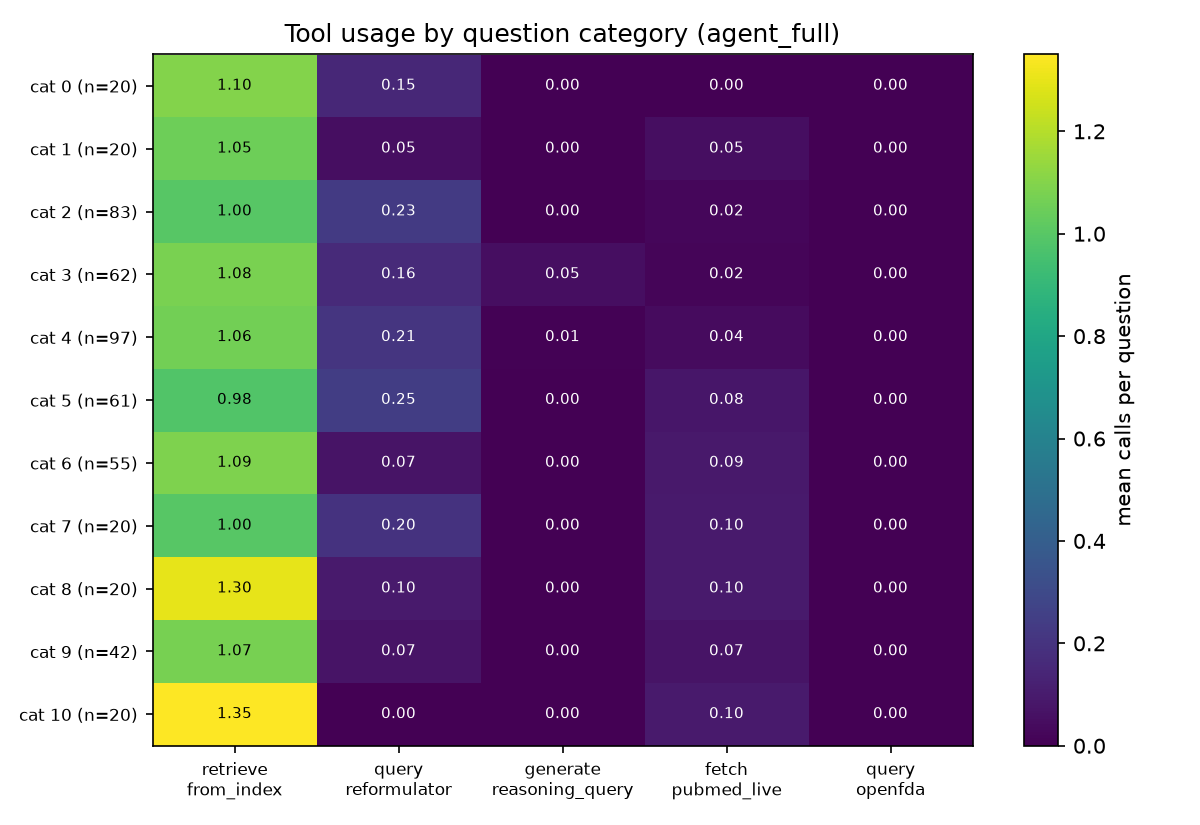

agent_full_guard


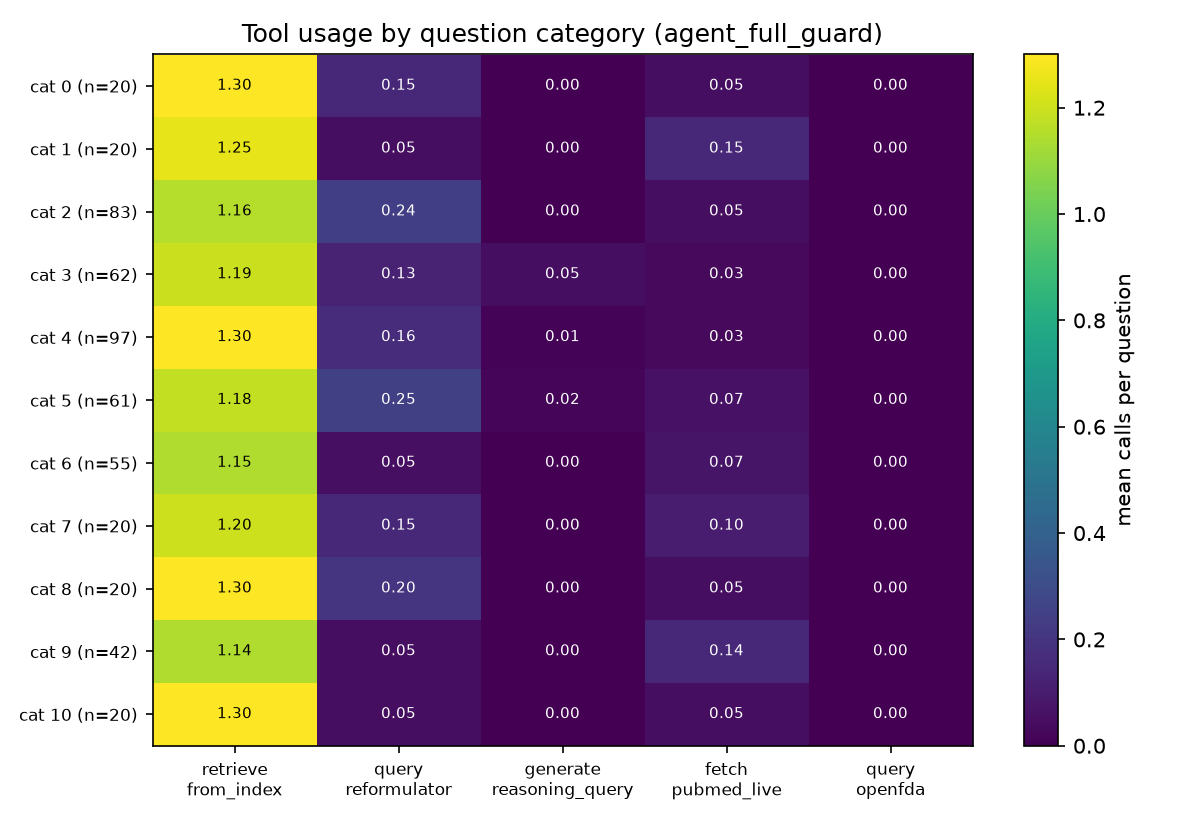

agent_full_granite_guardlocal


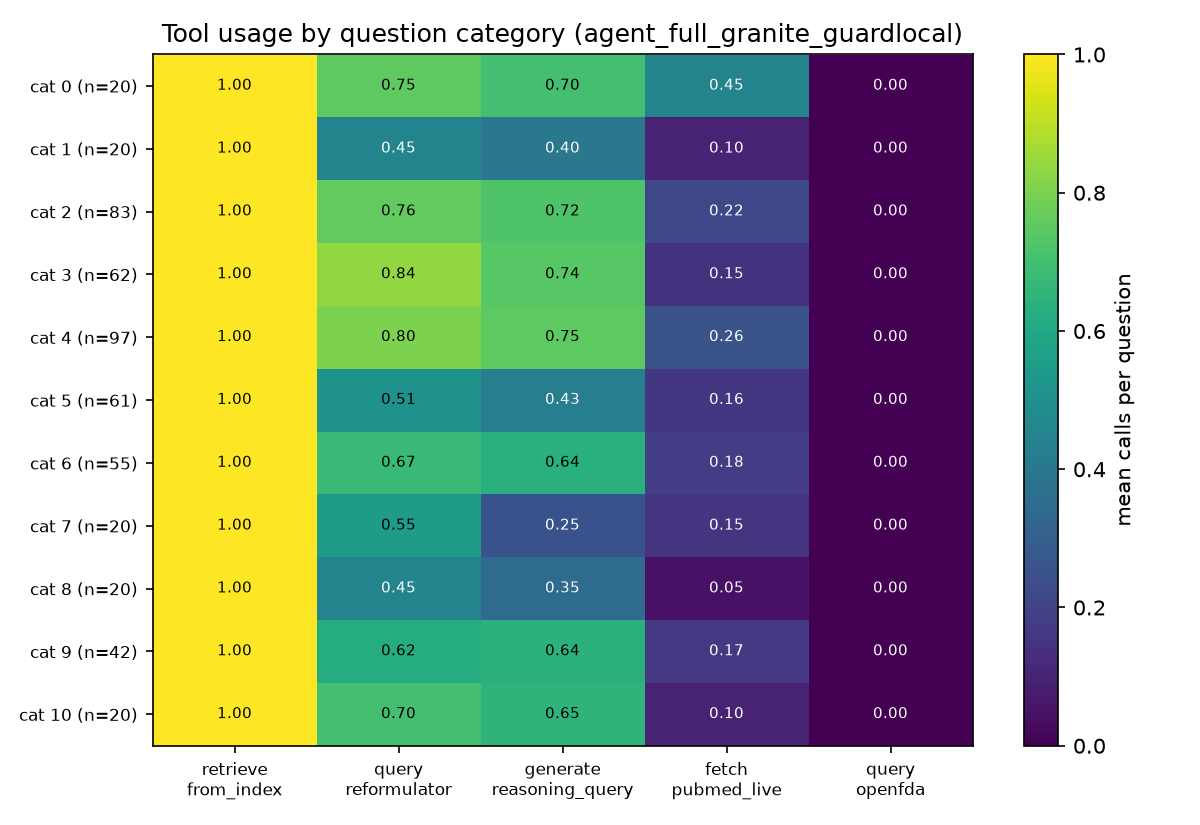

In [23]:
for name in ("agent_full", "agent_full_guard", "agent_full_granite_guardlocal"):    # MedGemma plain, MedGemma + guardrail, Granite + local-index guardrail
    print(name)
    if have(f"results/fig_tool_heatmap_{name}.png"):
        display(Image(str(ROOT / "results" / f"fig_tool_heatmap_{name}.png"), width=620))

### 🧭 Does a longer chain of thoughts help? (reasoning steps vs nDCG@10)

agent_full


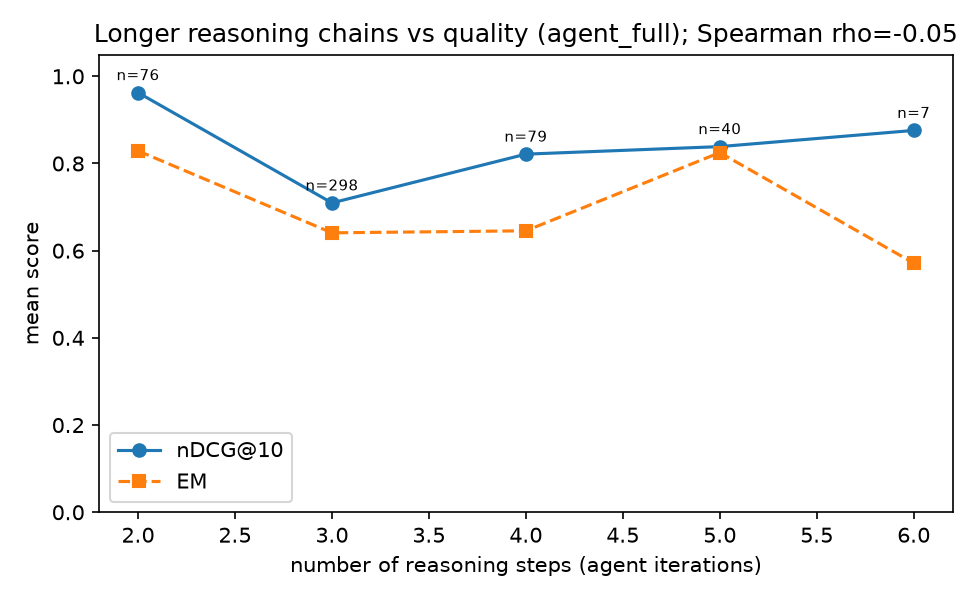

agent_full_guard


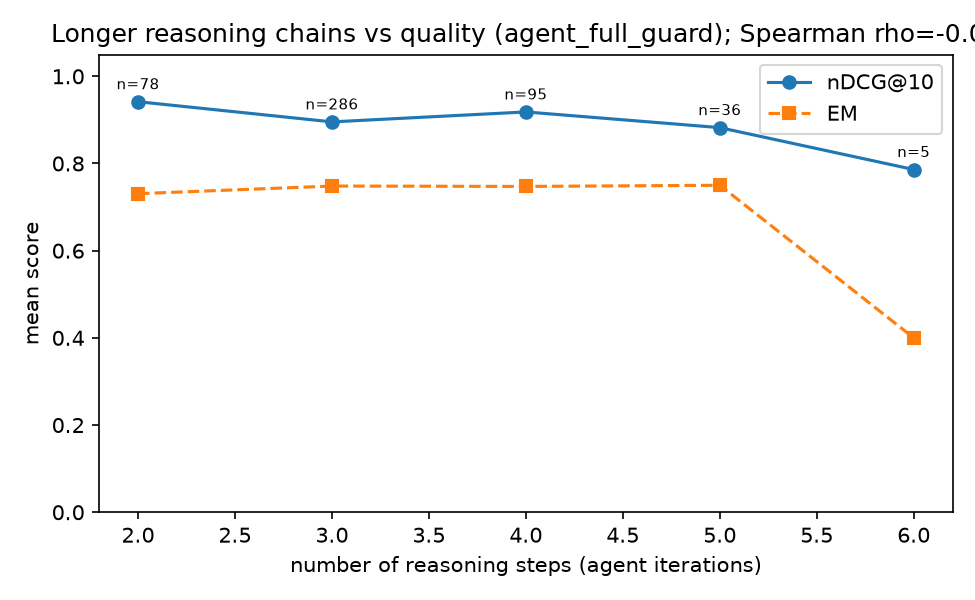

agent_full_granite_guardlocal


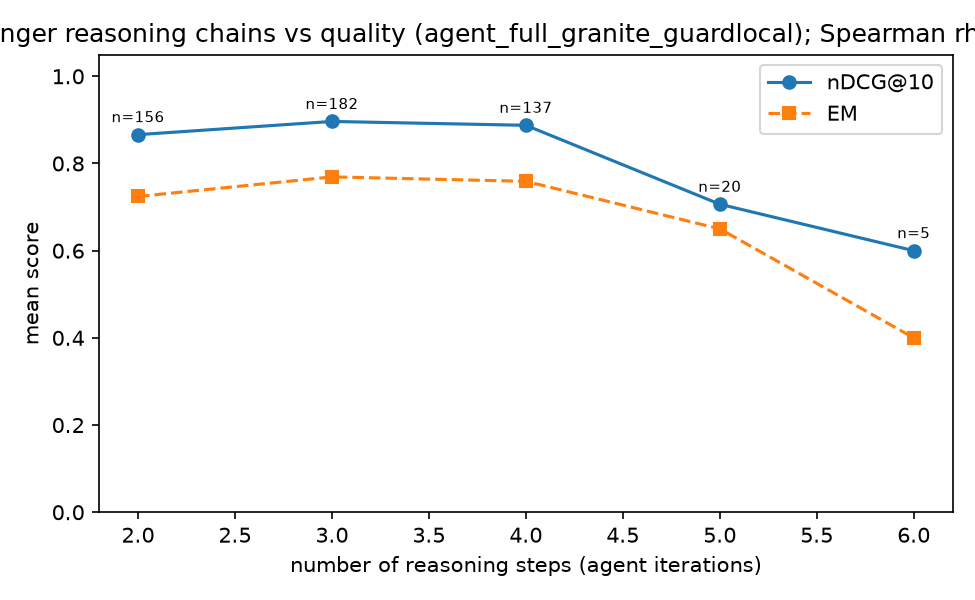

In [24]:
for name in ("agent_full", "agent_full_guard", "agent_full_granite_guardlocal"):
    if have(f"results/fig_steps_vs_ndcg_{name}.png"):
        print(name); display(Image(str(ROOT / "results" / f"fig_steps_vs_ndcg_{name}.png"), width=520))

The three agents shown below are the MedGemma scheduler without the guardrail, with the guardrail, and the Granite scheduler with the local-index guardrail. The guardrail removes most *retrieval misses*
(19.2 % → 6.6 % of questions for MedGemma) but not *looping* (about 81 % either way), which is why looping alone does not explain the loss.

### ⚠️ Failure modes
*looping* (repeats the same action), *format* (cannot be parsed), *stopped early* (answers without a tool),
*bad arguments* (unknown tool, tool error, empty PubMed query), *retrieval miss* (the gold paper never appears), *reading error* (it appears but the answer is wrong).

In [25]:
for name in ("agent_full", "agent_full_guard", "agent_full_granite_guardlocal"):
    if have(f"results/failure_rates_{name}.csv"):
        print(name); display(pd.read_csv(ROOT / "results" / f"failure_rates_{name}.csv", index_col=0).round(3).tail(1))   # the "all" row; per-category rows are in the csv

agent_full


,n,looping,format,stopped_early,bad_args,retrieval_miss,reading_error
cat_num,,,,,,,
all,500,0.818,0.082,0.0,0.016,0.192,0.188


agent_full_guard


,n,looping,format,stopped_early,bad_args,retrieval_miss,reading_error
cat_num,,,,,,,
all,500,0.814,0.086,0.0,0.02,0.066,0.216


agent_full_granite_guardlocal


,n,looping,format,stopped_early,bad_args,retrieval_miss,reading_error
cat_num,,,,,,,
all,500,0.04,0.0,0.0,0.034,0.1,0.196


### 🕵️ Why are more tools worse (without the guardrail)? A look at the tool sequences

We group the questions by the **sequence of tools** the agent used.

In [26]:
SHORT = {"retrieve_from_index": "RETR", "query_reformulator": "REFORM", "fetch_pubmed_live": "PUBMED",
         "generate_reasoning_query": "REASON", "query_openfda": "FDA"}

def sequence_table(name, top=8):
    rows = load_traces(name)
    if not rows: return None
    df = pd.DataFrame([{"sequence": " > ".join(SHORT[s["tool"]] for s in r["trace"] if s.get("executed")) or "(none)",
                        "EM": r["EM"], "gold_seen": r["gold_seen"]} for r in rows])
    g = df.groupby("sequence").agg(n=("EM", "size"), EM=("EM", "mean"), gold_seen=("gold_seen", "mean")).sort_values("n", ascending=False)
    used = df.sequence.str.contains("RETR")
    print(f"{name}: retrieve_from_index called in {used.mean():.0%} of questions | EM {df[used].EM.mean():.3f} with vs {df[~used].EM.mean():.3f} without")
    return g.head(top).round(3)

display(sequence_table("agent_full"))
display(sequence_table("agent_full_guard"))

agent_full: retrieve_from_index called in 86% of questions | EM 0.747 with vs 0.300 without


,n,EM,gold_seen
sequence,,,
RETR,305,0.757,0.944
RETR > RETR,82,0.707,0.939
REFORM,62,0.306,0.000
RETR > PUBMED,26,0.769,0.885
RETR > RETR > RETR,9,0.667,0.889
REFORM > REFORM,8,0.250,0.000
REFORM > RETR,2,1.000,1.000
RETR > REASON,2,0.500,1.000


agent_full_guard: retrieve_from_index called in 100% of questions | EM 0.742 with vs nan without


,n,EM,gold_seen
sequence,,,
RETR,297,0.754,0.933
RETR > RETR,93,0.742,0.935
REFORM > RETR,61,0.705,0.934
RETR > PUBMED,30,0.667,0.933
REFORM > REFORM > RETR,7,1.000,1.000
RETR > RETR > RETR,6,0.667,0.833
RETR > REASON,3,0.667,1.000
RETR > REASON > REASON,1,1.000,1.000


**The mechanism.** The reformulator and the reasoning tool return a *query*, not documents. A small model treats the call as "I searched" and stops,
so the answer generator receives **no evidence** and falls back to Baseline-0 accuracy (EM ≈ 0.30). That explains almost exactly the gap between the full and the index-only agent.

### 🛡️ A guardrail that keeps the tools' definition intact
If the agent stops with no document evidence, the system retrieves once (with the latest reformulated query, else the question) before answering.
**Prediction written before running:** both schedulers reach about 0.73–0.75, i.e. they catch up with Vanilla RAG.

In [27]:
if have("results/exp_ladder.csv"):
    ladder = pd.read_csv(ROOT / "results" / "exp_ladder.csv")
    display(ladder[ladder.system.str.contains("Agent")][["system", "EM", "Contains", "tool_calls", "steps", "latency_s", "R@10"]].round(3))

,system,EM,Contains,tool_calls,steps,latency_s,R@10
5,Agent: full (5 tools),0.684,0.730,1.292,3.208,3.482,0.832
6,Agent: index only,0.752,0.802,1.262,3.050,3.212,0.968
7,Agent (Granite scheduler): full,0.550,0.580,2.062,3.090,2.925,0.526
8,Agent: full + guardrail,0.742,0.796,1.436,3.208,3.408,0.968
9,Agent (Granite): full + guardrail,0.700,0.750,2.380,3.066,2.969,0.830
10,Agent (Granite): full + guardrail (local-index...,0.744,0.786,2.510,3.072,2.996,0.946
11,Agent: no OpenFDA + guardrail,0.754,0.804,1.474,3.254,3.429,0.970
12,Agent: no live PubMed + guardrail,0.756,0.802,1.286,3.128,3.220,0.972
13,Agent: no reasoning query + guardrail,0.756,0.812,1.500,3.318,3.362,0.968
14,Agent: no reformulator + guardrail,0.736,0.788,1.482,3.392,3.720,0.964


### 🧾 Side by side: fixed chain vs dynamic agent
**Annotated pairs** (MedGemma agent + guardrail vs Vanilla RAG; full traces in `results/trace_examples_agent_full_guard.md`). Of the 500 questions the agent is better on 13 and worse on 24.

| qid | gold | Vanilla RAG | Agent | What differed |
|---|---|---|---|---|
| 333 (better) | DRS1 | `DRS1 gene` (EM 0) | `DRS1` (EM 1) | Same paper, same facts. The agent is "better" only through answer wording (no extra word); it also repeated the same query twice and was stopped by the loop breaker. |
| 272 (better) | Opsonophagocytic activity (OPA) assay | `OPA` (EM 0) | `OPA assay` (EM 1) | The agent called only `query_reformulator` (3 times, 2 repeats), so it had no documents; the **guardrail** ran `retrieve_from_index` with the rewritten query and the gold paper was found. Again an answer-form difference decides EM. |
| 53 (worse) | covind19.org | `covind19.org` (EM 1) | `datahub.io` (EM 0) | After a first retrieval the agent also called `fetch_pubmed_live` and got generic COVID-vaccine papers; the answer generator then saw unrelated evidence beside the gold paper (gold seen = True) and answered wrongly: **evidence pollution** from an unnecessary tool. |
| 78 (worse) | Cytosolic leaflet of the plasma membrane | same (EM 1) | `Plasma membrane` (EM 0) | The gold paper was retrieved in both systems, but the agent's answer came out less specific; the agent used its own query wording, which probably changed the retrieved set (not verified). |
| 423 (worse) | Surgical decompression | same (EM 1) | `Anterior approach` (EM 0) | Reformulator loop, then guardrail retrieval with a query that is almost the question; a reading error on mostly equivalent evidence. |

**Granite scheduler + local-index guardrail** (`results/trace_examples_agent_full_granite_guardlocal.md`): better on 16 questions, worse on 26.

| qid | gold | Vanilla RAG | Agent | What differed |
|---|---|---|---|---|
| 333 (better) | DRS1 | `DRS1 gene` (EM 0) | `DRS1` (EM 1) | Granite follows the intended chain (reformulate → reasoning → retrieve → final answer in 4 steps). The gain is again answer wording. |
| 137 (better) | H-2K(b)-tsA58 transgenic mouse (immortomouse) | `H-2K(b)-tsA58 transgenic mice` (EM 0) | `Immortomice` (EM 1) | Granite stopped after the two rewriting tools without retrieving; the guardrail retrieved once. EM counts the synonym; wording again. |
| 189 (worse) | Angiotensin and acetylcholine | same (EM 1) | `P2X5 receptors` (EM 0) | The reformulated query ("CNS neurotransmitter regulation interaction substances pair") is more generic than the question; the gold paper was never retrieved. **Rewriting lost discriminative content.** |
| 319 (worse) | Acinetobacter baumannii | same (EM 1) | `Pseudomonas aeruginosa` (EM 0) | Granite put its own wrong guess into the PubMed query ("Pseudomonas aeruginosa multidrug resistance …"), got confirming papers, and the gold paper was never retrieved: **self-confirming search**. |
| 39 (worse) | Culture-specific intravenous antibiotics and surgical joint irrigation with graft retention | same (EM 1) | `Culture-specific intravenous (IV) antibiotics` (EM 0) | Gold paper retrieved; the answer is correct but incomplete (drops the surgical part), so exact match fails. |

**Take-aways.** (i) In both "agent better" examples shown, the difference is answer wording, not better orchestration (we did not audit all 13). (ii) Looping on an identical call is the norm for MedGemma (81% of questions) but does not by itself change the answer. (iii) The clearest *real* harms are an unnecessary extra tool adding irrelevant evidence (MedGemma, qid 53), a rewritten query that is more generic than the question (Granite, qid 189) and a scheduler that puts its own wrong guess into the search query (Granite, qid 319).

# 🆚 11. Granite vs MedGemma as the Scheduler

A tool-calling-oriented model (`ibm-granite/granite-4.0-micro`, 3B) schedules the tools; MedGemma still runs the LLM tools and writes the answers.
Same prompt, same tools: only the scheduler changes. (**Caveat:** the MedGemma scheduler prompt was refined three times on smoke tests, the Granite one never.)

,system,EM,tool_calls,steps,latency_s,R@1,R@10
5,Agent: full (5 tools),0.684,1.292,3.208,3.482,0.716,0.832
6,Agent: index only,0.752,1.262,3.050,3.212,0.832,0.968
7,Agent (Granite scheduler): full,0.550,2.062,3.090,2.925,0.448,0.526
8,Agent: full + guardrail,0.742,1.436,3.208,3.408,0.832,0.968
9,Agent (Granite): full + guardrail,0.700,2.380,3.066,2.969,0.698,0.830
10,Agent (Granite): full + guardrail (local-index...,0.744,2.510,3.072,2.996,0.796,0.946
15,Agent (Granite): no reformulator + guardrail*,0.752,1.350,2.120,1.743,0.808,0.960
16,Agent (Granite): no reasoning query + guardrail*,0.746,2.070,2.864,1.672,0.806,0.966
17,Agent (Granite): no live PubMed + guardrail*,0.744,2.448,3.036,2.992,0.800,0.944


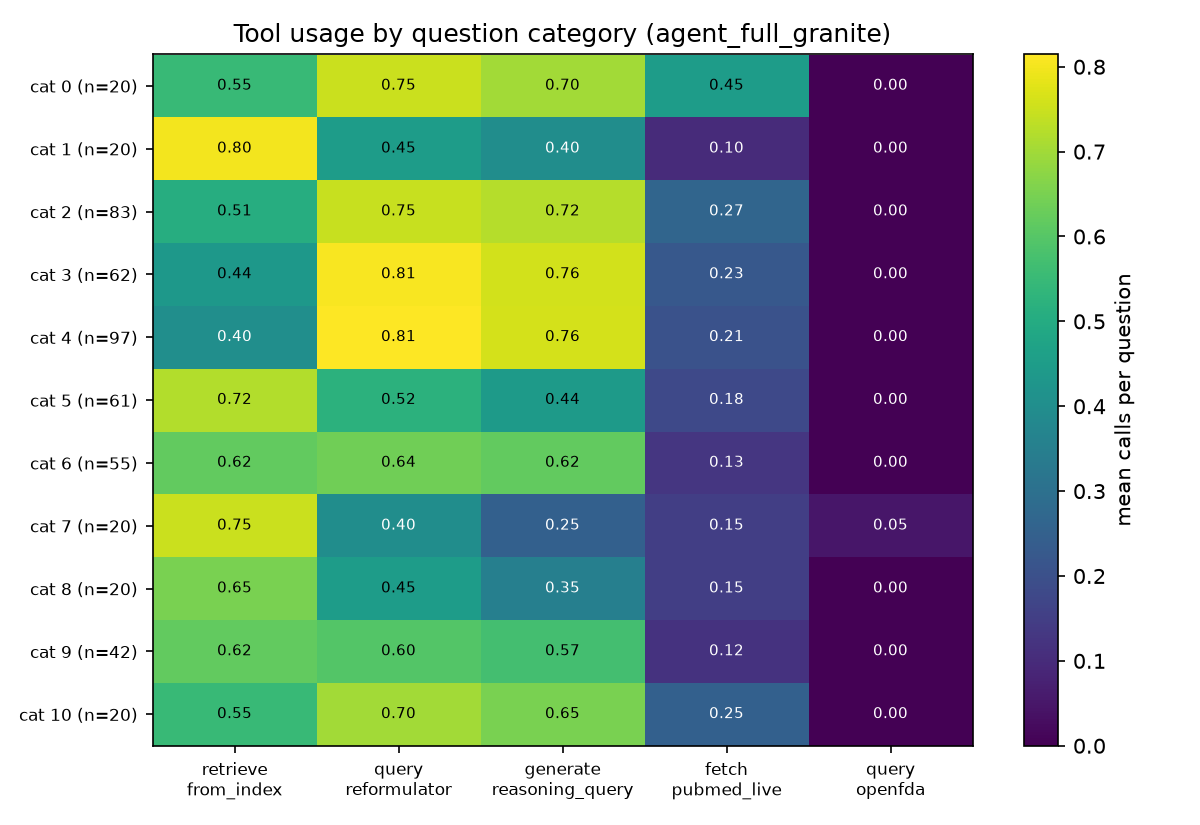

In [28]:
if have("results/exp_ladder.csv"):
    ladder = pd.read_csv(ROOT / "results" / "exp_ladder.csv")
    display(ladder[ladder.system.str.contains("Granite|Agent: full|index only")][["system", "EM", "tool_calls", "steps", "latency_s", "R@1", "R@10"]].round(3))
if have("results/fig_tool_heatmap_agent_full_granite.png"):
    display(Image(str(ROOT / "results" / "fig_tool_heatmap_agent_full_granite.png"), width=620))

**Reading the table.**
- Out of the box Granite is far worse than MedGemma (EM 0.550 vs 0.684, paired -0.134, significant): it uses all tools (2.06 per question) but treats the two query-rewriting tools as if they returned evidence, so 133 questions never reach the index.
- With the guardrail (retrieve once if there is no document evidence) Granite reaches 0.700, still below MedGemma + guardrail (0.742): in 65 questions (13%) it relied on PubMed papers alone (EM 0.431, gold paper seen in about 10%), and the guardrail does not fire when evidence exists.
- A *post-hoc* variant (designed after this diagnosis) also retrieves when the local index was never queried: Granite reaches **0.744**, inside the range predicted before the run (0.735-0.745), +0.044 over the original guardrail (CI [0.022, 0.068]) and equal to MedGemma + guardrail (0.742). MedGemma never used PubMed without the index (0 questions), so the variant is only relevant for Granite.
- So most of the Granite deficit was the tool-contract failure, not a lack of model ability; the remaining prompt-fit question is listed under limitations.

# 📝 12. An Extra Look: Paraphrased Questions

About half of the questions are paraphrased. Are they harder, and is the difficulty in *finding* the paper or in *reading* it?

In [29]:
if have("results/paraphrase_split.csv"):
    display(pd.read_csv(ROOT / "results" / "paraphrase_split.csv").round(3))

,system,EM_original,EM_paraphrased,gap(orig-para),gap_ci_lo,gap_ci_hi,n_orig,n_para,R@1_orig,R@1_para
0,baseline_none_v3,0.288,0.303,-0.014,-0.091,0.066,229,271,NaN,NaN
1,baseline_vanilla_rag_v3,0.821,0.716,0.105,0.032,0.180,229,271,0.825,0.834
2,baseline_reformulate_rag_v3,0.817,0.723,0.093,0.019,0.168,229,271,0.838,0.841
3,baseline_reasoning_rag_v3,0.773,0.705,0.068,-0.010,0.142,229,271,0.825,0.815
4,baseline_fda_rag_v3,0.817,0.712,0.104,0.031,0.176,229,271,0.825,0.834
5,agent_full,0.712,0.661,0.051,-0.030,0.130,229,271,0.707,0.723
6,agent_index_only,0.786,0.723,0.063,-0.015,0.139,229,271,0.843,0.823
7,agent_full_granite,0.568,0.535,0.033,-0.053,0.117,229,271,0.441,0.454


**Reading the table.** Paraphrased questions are harder for Vanilla RAG (about −10 EM points, significant), yet Recall@1 is the same for both groups:
the semantic retriever is not fooled by the changed wording; the loss comes from reading and matching the answer.

## 12b. How much does the answer-prompt wording matter?

We never searched for an optimal prompt, so we check sensitivity: Vanilla RAG and Baseline 0 are re-run with three reworded answer prompts
(v4 paraphrased instruction, v5 no format examples, v6 one-line instruction). Same model, same 500 questions, same retrieval; only the text changes.

In [30]:
if have("results/prompt_sensitivity.csv"):
    display(pd.read_csv(ROOT / "results" / "prompt_sensitivity.csv").round(3))
else:
    print("run scripts/14_prompt_sensitivity.py first")

,system,prompt,n,EM,Contains,ROUGE-1,diff_vs_v3,ci_lo,ci_hi
0,vanilla_rag,v3 (used in all experiments),500,0.764,0.820,0.860,0.000,0.000,0.000
1,vanilla_rag,v4 paraphrased instruction,500,0.776,0.830,0.866,0.012,-0.006,0.032
2,vanilla_rag,v5 no format examples,500,0.704,0.798,0.822,-0.060,-0.090,-0.030
3,vanilla_rag,v6 minimal instruction,500,0.718,0.818,0.814,-0.046,-0.076,-0.018
4,none,v3 (used in all experiments),500,0.296,0.310,0.417,0.000,0.000,0.000
5,none,v4 paraphrased instruction,500,0.292,0.308,0.422,-0.004,-0.022,0.014
6,none,v5 no format examples,500,0.206,0.270,0.384,-0.090,-0.122,-0.060
7,none,v6 minimal instruction,500,0.294,0.328,0.428,-0.002,-0.038,0.030


**Reading the table.** Wording matters, more than we hoped. Vanilla RAG moves between 0.704 and 0.776 EM (spread 0.072), the same size as the gaps between agent and fixed chains.
- A paraphrased instruction with the same examples (v4) is statistically the same as v3 (+0.012, CI [-0.006, 0.032]).
- Removing the format examples (v5, v6) costs 4.6-6.0 EM points (significant), but *Contains* barely moves (0.820 -> 0.798 / 0.818): the loss is answer *form* (length, modifiers), not knowledge.
- So v3 is on the plateau of "clear instruction + format examples", but we cannot claim it is optimal, and absolute EM should be read with about ±5 points of prompt uncertainty.
- All systems share the same prompt, so rankings are comparable; section 12c re-checks the fixed-chain ranking under v4.

## 12c. Does the ranking of the fixed chains survive a different prompt?

The four fixed chains and Baseline 0 are re-run with the paraphrased answer prompt v4 (same model, same 500 questions).

In [31]:
import json as _json
if have("results/stats_baselines_v4.json"):
    _s = _json.load(open(ROOT / "results" / "stats_baselines_v4.json"))
    _t = pd.DataFrame({k: {"EM": v["EM"]["mean"], "diff_vs_vanilla": _s["vs_ref"].get(k, {}).get("diff", 0.0),
                           "p_mcnemar": _s["vs_ref"].get(k, {}).get("p_mcnemar", float("nan"))} for k, v in _s["systems"].items()}).T
    display(_t.round(3)); print("oracle EM", round(_s["oracle"]["oracle_EM"], 3), "headroom", round(_s["oracle"]["headroom"], 3))

,EM,diff_vs_vanilla,p_mcnemar
none,0.292,-0.484,0.000
vanilla_rag,0.776,0.000,NaN
reformulate_rag,0.778,0.002,1.000
reasoning_rag,0.764,-0.012,0.327
fda_rag,0.776,0.000,1.000


oracle EM 0.808 headroom 0.03


**Reading the table.** Under v4 Vanilla RAG, reformulate→retrieve and FDA-augmented RAG are indistinguishable (0.776, 0.778, 0.776) and no chain beats Vanilla RAG, as under v3; the oracle headroom is again about +3 points (0.030 vs 0.032).
One detail does change: the reasoning→retrieve penalty (v3: -0.028, p = 0.02) shrinks to -0.012 and is not significant (p = 0.33), so we only claim that the reasoning chain is *not better* than Vanilla RAG, not that it is worse.
The conclusions "retrieval is what matters" and "no fixed chain clearly beats plain retrieval" do not depend on the prompt wording.

## 12d. Held-out validation: 500 new questions

Prompts, the agent loop and the guardrail were developed while looking at the first 500 questions. To check that the conclusions are not an artefact of that, every system was **frozen** and run on
**500 new questions** (`data/holdout.jsonl`): questions whose gold abstracts were already in the 5,000-paper index as distractors, same category counts as the development sample except
category 7 (only 10 available; 10 extra questions in category 4). The predictions below were written *before* the runs.

| | Prediction (written before the run) |
|---|---|
| P1 | Baseline 0 EM in [0.22, 0.36]; Vanilla RAG EM in [0.70, 0.82] |
| P2 | Vanilla, reformulate and FDA chains within ±0.03 of each other; no fixed chain significantly beats Vanilla |
| P3 | The unmodified MedGemma full agent is at least 0.04 below Vanilla (significant) |
| P4 | The guardrail lifts the MedGemma full agent by at least +0.03 (significant); MedGemma + guardrail is not significantly above Vanilla |
| P5 | Granite full < MedGemma full; Granite + local-index guardrail within 0.04 of MedGemma + guardrail; no Granite variant significantly above Vanilla |
| P6 | The index-only agent is not significantly different from Vanilla |

In [32]:
if have("results/holdout/exp_ladder.csv"):
    display(pd.read_csv(ROOT / "results" / "holdout" / "exp_ladder.csv")[["system", "EM", "Contains", "tool_calls", "steps", "latency_s", "R@1", "R@10"]].round(3))
else:
    print("run the held-out experiments first (README section 5)")

,system,EM,Contains,tool_calls,steps,latency_s,R@1,R@10
0,Baseline 0 (no tools),0.248,0.268,0.000,1.000,0.122,NaN,NaN
1,Vanilla RAG,0.746,0.772,1.000,1.000,0.177,0.844,0.956
2,Reformulate -> retrieve,0.746,0.770,2.000,2.000,0.279,0.846,0.958
3,Reasoning -> retrieve,0.744,0.766,2.000,2.000,0.601,0.824,0.956
4,FDA-augmented RAG,0.744,0.770,2.000,2.000,0.570,0.844,0.956
5,Agent: full (5 tools),0.644,0.684,1.326,3.182,3.428,0.716,0.800
6,Agent: index only,0.726,0.756,1.252,3.012,3.162,0.848,0.958
7,Agent (Granite scheduler): full,0.518,0.550,2.050,3.086,3.200,0.418,0.498
8,Agent: full + guardrail,0.722,0.754,1.490,3.226,3.427,0.846,0.956
9,Agent (Granite): full + guardrail,0.682,0.720,2.344,3.050,3.020,0.720,0.834


**Result: all six predictions held.**

| | Prediction | Held-out result | |
|---|---|---|---|
| P1 | Baseline 0 in [0.22, 0.36]; Vanilla in [0.70, 0.82] | 0.248; 0.746 | yes |
| P2 | fixed chains within ±0.03 of Vanilla, none significantly better | 0.746 / 0.744 / 0.744; all paired differences ≤ 0.002, p = 1.0 | yes |
| P3 | MedGemma full ≥ 0.04 below Vanilla | 0.644, −0.102 (CI [−0.138, −0.068]) | yes |
| P4 | guardrail ≥ +0.03; guarded agent not above Vanilla | +0.078 (CI [+0.050, +0.108]); 0.722 vs 0.746, −0.024 (CI [−0.048, 0.000], p = 0.073) | yes |
| P5 | Granite full < MedGemma full; local-index Granite within 0.04 of guarded MedGemma; none above Vanilla | 0.518 < 0.644; 0.708 vs 0.722 (−0.014); best Granite variant 0.038 *below* Vanilla (significant) | yes |
| P6 | index-only not different from Vanilla | 0.726 vs 0.746, −0.020 (CI [−0.046, +0.006], p = 0.164) | yes |

What the held-out run adds:
- The development conclusions replicate on new questions: the unmodified agent loses about 10 EM points to every fixed chain, in 10 of 11 categories, and the loss comes with Recall@10 falling from 0.956 to 0.800.
- The guardrail repairs most of the loss on both samples (+0.058 on development, +0.078 held-out), and the guarded MedGemma agent stays close to, but below, Vanilla RAG on both: -0.022 (p = 0.099) on development and -0.024 (p = 0.073) held-out. This is a replication, not a shrinking effect.
- The index-only agent (+0.082 over the full agent, as +0.068 on development) is again statistically indistinguishable from Vanilla. No configuration of the dynamic agent beats the fixed chains, on either sample.
- Granite is the weaker scheduler (0.518 vs 0.644 unguarded). The original guardrail leaves it 4.0 points behind guarded MedGemma (significant). The local-index variant was designed on the development sample, where it was 2.0 points below Vanilla RAG (not significant); on held-out data it is 3.8 points below (significant). This is the one result that moved the way tuning on the development sample would predict.
- Not repeated on held-out data: the per-tool ablations of section 8. Those are therefore development-sample results only.
- Caveat: the held-out set has 10 category-7 questions (not 20) and 10 extra in category 4; category-level rows are noise at these sizes.

## 12e. Coverage experiment: what if the local index does not contain the answer?

On our sample the local index almost always contains the gold paper (Recall@10 0.97), which leaves a dynamic agent little to decide. Here we remove that comfort.
On the 500 held-out questions the gold paper of a fixed random **0 %, 50 % or 100 %** of the questions is withheld from the index (the sets are nested; implemented as a filter at search time).
For a withheld question only live PubMed (`fetch_pubmed_live`) can still find the paper. To keep the comparison fair, the fixed side gets the same tools:
*reformulate → PubMed* and *retrieve + PubMed* (both always call PubMed). The agent is compared with itself **without** PubMed. All systems are frozen; the predictions were written before the runs.

| | Prediction (written before the run) |
|---|---|
| C1 | Vanilla RAG EM falls to 0.44-0.58 with 50 % withheld and to 0.20-0.34 with 100 % withheld (Baseline 0 is 0.248) |
| C2 | Live PubMed recovers the gold paper only for a minority (10-40 % of withheld questions, retrieve + PubMed chain); that chain beats Vanilla RAG by 0.04-0.20 at 100 % |
| C3 | The agent does **not** notice that the index is incomplete: its share of questions with a PubMed call differs by less than 0.10 between withheld and retained questions (50 % level) and stays below 0.30 at 100 % |
| C4 | Hence PubMed adds little inside the agent: full + guardrail minus no-PubMed + guardrail is not significant at 50 % and at most +0.05 at 100 % |
| C5 | The always-PubMed hybrid chain is at least as good as the agent at 100 % withheld; at 0 % it is within -0.05..0 of Vanilla RAG (extra documents distract) |

,system,withheld_%,EM,EM_withheld_qs,EM_retained_qs,tool_calls,latency_s,gold_seen_withheld_qs,gold_seen_retained_qs
0,Baseline 0 (no tools),0,0.248,NaN,0.248,0.000,0.122,NaN,NaN
1,Baseline 0 (no tools),50,0.248,0.224,0.272,0.000,0.122,NaN,NaN
2,Baseline 0 (no tools),100,0.248,0.248,NaN,0.000,0.122,NaN,NaN
3,Vanilla RAG,0,0.746,NaN,0.746,1.000,0.177,NaN,NaN
4,Vanilla RAG,50,0.488,0.216,0.760,1.000,0.196,NaN,NaN
5,Vanilla RAG,100,0.220,0.220,NaN,1.000,0.189,NaN,NaN
6,Reformulate -> retrieve,0,0.746,NaN,0.746,2.000,0.279,NaN,NaN
7,Reformulate -> retrieve,50,0.484,0.220,0.748,2.000,0.309,NaN,NaN
8,Reformulate -> retrieve,100,0.222,0.222,NaN,2.000,0.309,NaN,NaN
9,Reformulate -> PubMed (chain),0,0.336,NaN,0.336,2.000,0.952,NaN,0.090


,withheld_%,pubmed_used_overall,pubmed_used_withheld_qs,pubmed_used_retained_qs,index_used_overall,gold_seen_withheld_qs,gold_seen_retained_qs
0,0,0.040,NaN,0.040,1.0,NaN,0.914
1,50,0.072,0.108,0.036,1.0,0.040,0.920
2,100,0.070,0.070,NaN,1.0,0.018,NaN


,comparison,withheld_%,EM_a,EM_b,diff,ci_lo,ci_hi,only_a,only_b,p_mcnemar,significant
0,PubMed tool effect (agent),0,0.722,0.730,-0.008,-0.028,0.012,11,15,0.5572,False
1,PubMed tool effect (agent),50,0.490,0.494,-0.004,-0.028,0.020,17,19,0.8679,False
2,PubMed tool effect (agent),100,0.240,0.240,0.000,-0.024,0.022,17,17,1.0000,False
3,agent vs Vanilla RAG,0,0.722,0.746,-0.024,-0.048,0.000,13,25,0.0730,False
4,agent vs Vanilla RAG,50,0.490,0.488,0.002,-0.022,0.028,21,20,1.0000,False
5,agent vs Vanilla RAG,100,0.240,0.220,0.020,-0.006,0.046,28,18,0.1839,False
6,agent vs always-PubMed hybrid chain,0,0.722,0.730,-0.008,-0.038,0.020,27,31,0.6940,False
7,agent vs always-PubMed hybrid chain,50,0.490,0.528,-0.038,-0.070,-0.004,23,42,0.0248,True
8,agent vs always-PubMed hybrid chain,100,0.240,0.338,-0.098,-0.132,-0.062,17,66,0.0000,True
9,hybrid chain vs Vanilla RAG,0,0.730,0.746,-0.016,-0.044,0.012,21,29,0.3222,False


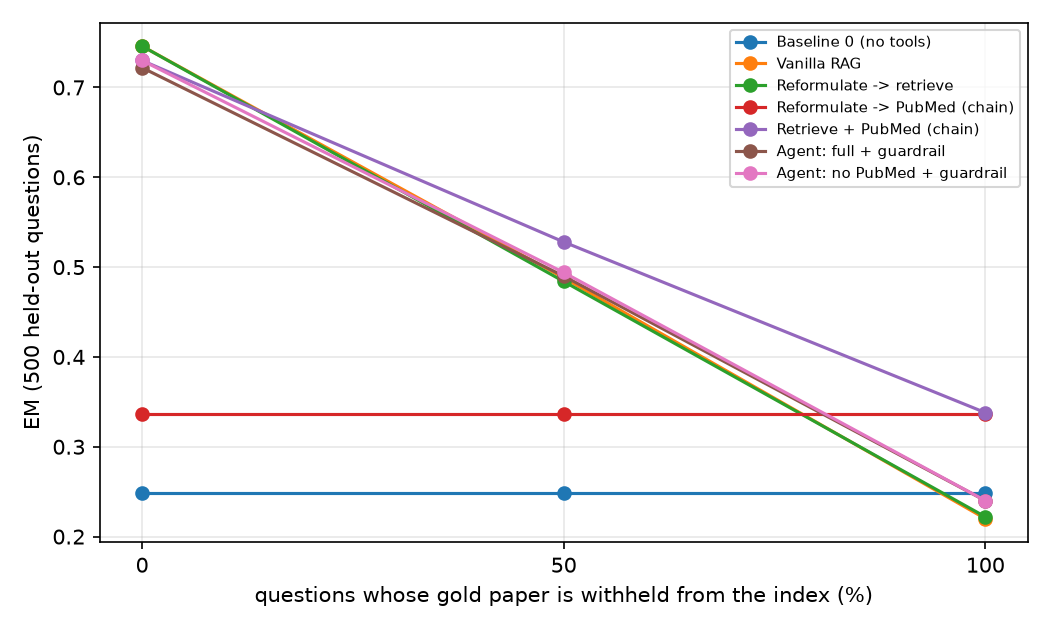

In [33]:
if have("results/coverage/coverage_em.csv"):
    display(pd.read_csv(ROOT / "results" / "coverage" / "coverage_em.csv"))
    display(pd.read_csv(ROOT / "results" / "coverage" / "coverage_switching.csv"))
    display(pd.read_csv(ROOT / "results" / "coverage" / "coverage_pairs.csv"))
if have("results/coverage/fig_coverage.png"):
    display(Image(str(ROOT / "results" / "coverage" / "fig_coverage.png"), width=620))

**Result: four of the five predictions held; C2 held only in part.**

| | Prediction | Result | |
|---|---|---|---|
| C1 | Vanilla 0.44-0.58 (50 %) and 0.20-0.34 (100 %) | 0.488 and 0.220 | yes |
| C2 | PubMed finds the gold paper for 10-40 % of withheld questions; retrieve + PubMed beats Vanilla by 0.04-0.20 at 100 % | gold paper found for **8.4-9.0 %** (just below the range); +0.118 | **first half no**, second half yes |
| C3 | the agent does not notice missing coverage (PubMed-call share differs by < 0.10; < 0.30 at 100 %) | 10.8 % of withheld vs 3.6 % of retained questions (difference 0.072); 7.0 % at 100 % | yes |
| C4 | PubMed adds little inside the agent | full + guardrail minus no-PubMed: -0.004 (50 %), 0.000 (100 %), both not significant | yes |
| C5 | the always-PubMed chain is at least as good as the agent at 100 %; within -0.05..0 of Vanilla at 0 % | +0.098 over the agent (p < 0.001); -0.016 vs Vanilla | yes |

What the experiment shows:
- **Coverage is what limits accuracy.** Vanilla RAG falls from 0.746 to 0.488 to 0.220 as 0 / 50 / 100 % of the gold papers are withheld. At 100 % it is even below Baseline 0 (0.248): unrelated abstracts do not help (we did not test this small difference).
- **Live PubMed is a weak but real substitute.** Keyword search finds the exact source paper for only about 9 % of the questions, yet the PubMed-only chain is 0.088 above no tools (CI [0.052, 0.124]) and retrieve + PubMed is 0.118 above Vanilla RAG at 100 %: related abstracts often carry the needed fact even when they are not the source paper.
- **The agent does not use it.** It calls PubMed on 10.8 % of the withheld questions (3.6 % of the retained ones, 7.0 % overall at 100 %), roughly three times more often when the index cannot answer, but from a very low base: about nine withheld questions in ten get no PubMed call. As a result the agent with PubMed is not better than the same agent without it.
- **A fixed chain that always calls both tools beats the agent exactly where the tool matters:** -0.038 at 50 % (p = 0.025) and -0.098 at 100 % (p < 0.001); at 0 % there is no difference (-0.008). So the extra tool has value, and the failure is the *decision* to use it, not a lack of value.
- Descriptive split at 50 % (250 questions each; not tested): the agent against Vanilla is +0.044 on withheld and -0.040 on retained questions (net +0.002); PubMed inside the agent is +0.028 on withheld and -0.036 on retained questions, which fits "helps when needed, adds noise when not".
- Caveats: one random withheld subset per level (seed 0); MedGemma scheduler only (no Granite run); PubMed queries are written by the LLM and PubMed ANDs all terms, so a better query strategy might find the gold paper more often; live PubMed results are stored in `cache/` for reproducibility.

# 🧠 13. Discussion, Limitations and Related Work

## Conclusion

*Does dynamic orchestration beat a fixed retrieval pipeline?* **Not in our setting, on either sample.** With a small zero-shot scheduler, no agent configuration is better than plain Vanilla RAG
(EM 0.764 on the 500 development questions, 0.746 on the 500 frozen held-out questions). The best agents come close but stay below it:

| | development | held-out | vs Vanilla RAG (dev / held-out) |
|---|---|---|---|
| MedGemma agent, all tools, no guardrail | 0.684 | 0.644 | -0.080 / -0.102 (both significant) |
| MedGemma agent + guardrail | 0.742 | 0.722 | -0.022 (p = 0.099) / -0.024 (p = 0.073) |
| MedGemma agent, index only | 0.752 | 0.726 | -0.012 / -0.020 (not significant) |
| Granite agent + local-index guardrail | 0.744 | 0.708 | -0.020 (n.s.) / -0.038 (significant) |

and they cost roughly 15-20 times the latency (3.0-3.4 s per question against 0.18-0.19 s). The held-out run is the strongest piece of evidence: the six predictions written before it all held (section 12d). The coverage experiment (section 12e) removes the most favourable excuse for this result, a retriever that already finds everything: when the local index is incomplete a fixed chain that always calls PubMed still beats the agent (+0.038 at 50 % and +0.098 at 100 % withheld).

## What we found

- **Retrieval is what matters:** EM 0.30 → 0.76. On top of it, no tool or orchestrator improves reliably (rewriting, reasoning queries and OpenFDA change EM by at most a few points).
- **Without the guardrail the extra tools hurt** (-8 EM points on development, -10 held-out), because of the "query without evidence" failure: the rewriting tools return a query, the small scheduler stops, and the answer generator gets no documents.
- **With the guardrail no single tool matters** (development sample only; not repeated held-out): removing OpenFDA, PubMed, the reasoning tool or the reformulator changes EM by -0.006 to +0.014 for MedGemma and 0.000 to +0.008 for Granite, with every 95 % CI including 0 (about ±0.025). OpenFDA is never called. The tools only add time: Granite without the reasoning tool or the reformulator is as accurate at about 1.7 s instead of 3.0 s. An ablation can only say "no detectable effect", not "zero effect".
- A tool-calling model (Granite) really uses all tools and stops by itself, but misunderstands what the rewriting tools return; it is also the weaker scheduler (-4 points with the original guardrail, significant on both samples).
- **When the index is incomplete the extra tool becomes useful, but the agent does not exploit it** (section 12e): a fixed chain that always adds live PubMed is +0.118 over Vanilla RAG at 100 % withheld, while the agent calls PubMed on only 7-11 % of the questions and ends up 0.098 behind that chain.
- Our retrieval baseline is strong (Recall@10 0.97) and the oracle over the four fixed chains is only about +3 to +5 points: little room for any orchestrator.

**Limitations.** 500 questions per sample (a paired difference needs about ±2 points to be detectable); a closed 5,000-paper corpus (the dataset paper searches 16M abstracts, so absolute numbers are not comparable);
the answer prompt, the agent prompt and the guardrail were developed by reading failures on the development sample. We then froze every system and re-ran it on 500 new questions: the conclusions hold, the guarded MedGemma gap to Vanilla RAG is unchanged (-0.022 vs -0.024), and only the Granite local-index guardrail variant, which was designed on the development sample, looks worse on new data (-0.020 → -0.038). The held-out set has 10 questions in category 7 (not 20) and 10 extra in category 4, so per-category numbers are noise, and the per-tool ablation was not repeated on it. There is no systematic prompt search (prompt wording moves EM by about ±5 points, section 12b), so the prompts are shared and fixed, not optimal;
the scheduler prompt was developed with MedGemma and reused unchanged for Granite, so part of the Granite gap may be prompt fit; only zero-shot small schedulers were tested (no few-shot tool demos, no fine-tuning, no larger LLM);
the coverage experiment uses one random withheld subset per level and only the MedGemma scheduler; the BM25 and hybrid baselines are evaluated for retrieval quality only, not end to end; the guardrail is a post-hoc fix (its effect was predicted before the run); EM underestimates correct answers with different wording, and we did not audit the errors one by one.

**Related work.**
- *Benchmark.* PaperSearchQA (Burgess et al., 2026) introduces the questions; it searches 16M abstracts and trains a search agent with RL (Search-R1, Jin et al., 2025). We do not train anything and search 5,000 abstracts, so absolute numbers are not comparable.
- *Agent loop.* We use the ReAct pattern (Yao et al., 2022). Splitting a *planner* from an answer writer follows the multi-LLM idea of α-UMi (Shen et al., 2024), whose authors report that small models are weak tool users; FireAct (Chen et al., 2023) fine-tunes agents for this reason.
- *When to retrieve.* Self-RAG (Asai et al., 2024) and Adaptive-RAG (Jeong et al., 2024) learn to decide whether and how much to retrieve. Our zero-shot schedulers have no such training, which is consistent with the failures we observe (stopping without evidence, looping).
- *Query rewriting.* Rewriting helps weak retrievers, but Weller et al. (2024) show that expansions can hurt strong ones; with Recall@10 of 0.97 our reformulate and reasoning chains are not better than plain retrieval.
- *Evaluation.* Exact match underestimates correct answers (Kamalloo et al., 2023), hence the Contains and ROUGE columns; we use paired bootstrap and McNemar tests rather than comparing point estimates.

# ♻️ 14. Reproducibility

Every number in this notebook comes from `results/` and `traces/`, produced by the numbered scripts in `scripts/` (see `README.md` for the exact commands and SLURM jobs).
Seed 42, greedy decoding, bf16, one question per PMID. All runs are resumable.